# 02 · Itens e pagamentos

A validação dos pedidos definiu o recorte de **jan/2017 a ago/2018** e mostrou que o volume de pedidos cresce no período. Para um investidor, porém, volume não basta: a pergunta que guia este notebook é

> **A Olist cresce também em valor vendido, e esse valor é confiável?**

Duas tabelas respondem a ela: **itens** (`order_items`), com o preço e o frete de cada produto vendido, e **pagamentos** (`order_payments`), com o que o cliente efetivamente pagou.

## 2.1 Leitura da tabela de itens

Carrego itens e pedidos (preciso da data de compra e do status, que estão em `orders`) e repito o estilo dos gráficos do notebook 01.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

AZUL, LARANJA, CINZA = '#2a78d6', '#eb6834', '#a3a29d'
plt.rcParams.update({
    'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#a3a29d', 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.grid.axis': 'y',
})

orders = pd.read_csv('../data/raw/olist_orders_dataset.csv')
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])

items = pd.read_csv('../data/raw/olist_order_items_dataset.csv')
print(items.shape)
items.head()

(112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


**112.650 linhas**, contra 99.441 pedidos. Cada linha traz um `order_item_id` (1, 2, 3...), um produto e um vendedor.

**Hipótese:** cada linha é um **item** do pedido, e não um pedido. Se for assim, o mesmo `order_id` se repete quando o pedido tem mais de um item.

## 2.2 Granularidade: quantos itens tem cada pedido

Para testar, conto as linhas de cada pedido com `groupby('order_id').size()` e, sobre esse resultado, uso `value_counts()` para ver quantos pedidos têm 1, 2, 3 itens.

In [2]:
itens_por_pedido = items.groupby('order_id').size()
print('Pedidos distintos na tabela de itens:', items['order_id'].nunique())
itens_por_pedido.value_counts().sort_index()

Pedidos distintos na tabela de itens: 98666


1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
20        2
21        1
Name: count, dtype: int64

- **98.666 pedidos** distintos, e **88.863** deles (90%) têm um único item. Os demais têm de 2 a 21 itens.
- A hipótese se confirma: a tabela está no nível de **item**.

Não existe coluna de quantidade. Suspeito que duas unidades do mesmo produto apareçam como duas linhas. Para testar, comparo, nos pedidos com mais de um item, o número de linhas com o número de produtos diferentes (`nunique`).

In [3]:
por_pedido = items.groupby('order_id').agg(linhas=('order_item_id', 'size'),
                                           produtos=('product_id', 'nunique'))
varios = por_pedido[por_pedido['linhas'] > 1]
print('Pedidos com mais de um item:', len(varios))
print('Desses, com um único produto repetido:', (varios['produtos'] == 1).sum())

Pedidos com mais de um item: 9803
Desses, com um único produto repetido: 6567


Dos **9.803** pedidos com mais de um item, **6.567** repetem um único produto. A quantidade vendida aparece como **linhas repetidas**.

**Decisão:** o valor de um pedido é a **soma das suas linhas**. Antes de juntar itens com pedidos, resumo a tabela para uma linha por pedido; juntar sem resumir repetiria o pedido a cada item.

## 2.3 Vazios e duplicatas

Uso `isnull().sum()` para os vazios e `duplicated()` para linhas repetidas. Como a quantidade vem em linhas repetidas, uma linha idêntica a outra poderia ser legítima; por isso testo também o par `order_id` + `order_item_id`, que deveria identificar cada linha.

In [4]:
print(items.isnull().sum())
print()
print('Linhas idênticas:', items.duplicated().sum())
print('Pares pedido + nº do item repetidos:', items.duplicated(subset=['order_id', 'order_item_id']).sum())

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Linhas idênticas: 0


Pares pedido + nº do item repetidos:

 0


Nenhum vazio, nenhuma duplicata. O par `order_id` + `order_item_id` é a chave da tabela: as linhas repetidas do mesmo produto se diferenciam pelo número do item.

## 2.4 Ligação com a tabela de pedidos

Uma tabela de itens só serve se cada item pertence a um pedido conhecido. Com `isin()` confiro os dois sentidos: itens sem pedido (órfãos) e pedidos sem item.

In [5]:
itens_orfaos = ~items['order_id'].isin(orders['order_id'])
pedidos_sem_item = orders[~orders['order_id'].isin(items['order_id'])]

print('Itens sem pedido:', itens_orfaos.sum())
print('Pedidos sem item:', len(pedidos_sem_item))
pedidos_sem_item['order_status'].value_counts()

Itens sem pedido: 0
Pedidos sem item: 775


order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

- **Nenhum item órfão.**
- **775 pedidos sem item**, e **767** deles estão como `unavailable` (603) ou `canceled` (164): pedidos que não viraram venda. Os outros 8 estão parados em `created`, `invoiced` e `shipped`, o grupo de pedidos travados visto na validação de `orders`.

**Decisão:** esses pedidos não têm valor a somar e não alteram o valor vendido. Ficam fora sem tratamento.

## 2.5 Preço e frete

Com `.describe()` vejo a distribuição de preço e frete por item. Comparo média e mediana: quando a média fica muito acima da mediana, poucos valores altos puxam a média.

In [6]:
items[['price', 'freight_value']].describe().round(2)

,price,freight_value
count,112650.00,112650.00
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
25%,39.90,13.08
50%,74.99,16.26
75%,134.90,21.15
max,6735.00,409.68


- **Preço:** mediana de **R\$ 74,99** e média de **R\$ 120,65**. A média é 60% maior que a mediana, sinal de poucos itens caros puxando a média para cima.
- **Frete:** mediana de R\$ 16,26 e média de R\$ 19,99, mais próximas.
- O maior preço é **R\$ 6.735**.

**Hipótese:** os preços altos são produtos caros de verdade, e não erros de digitação. Para testar, conto quantos itens passam do limite do boxplot (Q3 + 1,5 × IQR) e olho os cinco maiores com o frete ao lado: se forem produtos reais, o frete também tende a ser alto.

In [7]:
q1 = items['price'].quantile(0.25)
q3 = items['price'].quantile(0.75)
limite = q3 + 1.5 * (q3 - q1)

acima = items['price'] > limite
print(f'Limite: R$ {limite:.2f}')
print(f'Itens acima do limite: {acima.sum():,} ({acima.mean() * 100:.1f}%)')
items.sort_values('price', ascending=False)[['price', 'freight_value']].head()

Limite: R$ 277.40
Itens acima do limite: 8,427 (7.5%)


,price,freight_value
3556,6735.0,194.31
112233,6729.0,193.21
107841,6499.0,227.66
74336,4799.0,151.34
11249,4690.0,74.34


- **8.427 itens (7,5%)** passam de R\$ 277,40. É uma fatia grande demais para ser erro de digitação: é a cauda de produtos mais caros.
- Os cinco maiores preços têm frete entre R\$ 74 e R\$ 228, bem acima da mediana de R\$ 16.

Cinco itens são pouco para dizer que o frete acompanha o preço. Para ver o comportamento dos 112 mil itens, uso um **gráfico de dispersão** (`plt.scatter`), com o preço no eixo x e o frete no eixo y; cada ponto é um item. Calculo também a **correlação** com `.corr()`, que vai de -1 a 1: perto de 0, os dois não andam juntos; perto de 1, sobem juntos.

               price  freight_value
price           1.00           0.41
freight_value   0.41           1.00
Itens com frete maior que o preço: 3.7%


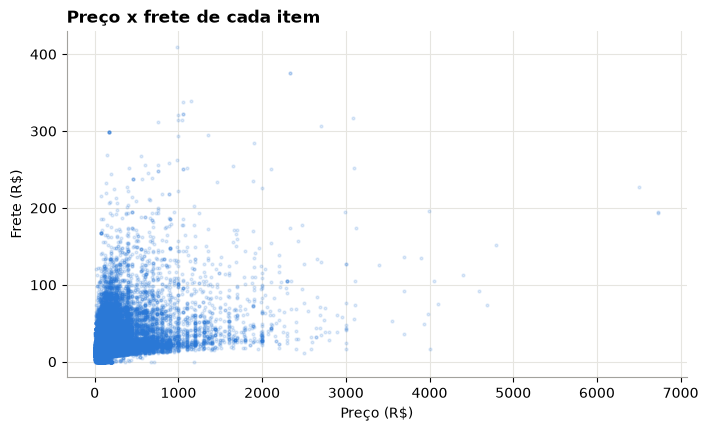

In [8]:
print(items[['price', 'freight_value']].corr().round(2))
print(f'Itens com frete maior que o preço: {(items["freight_value"] > items["price"]).mean() * 100:.1f}%')

plt.figure(figsize=(8, 4.5))
plt.scatter(items['price'], items['freight_value'], s=4, alpha=0.15, color=AZUL)
plt.grid(True, axis='both')
plt.title('Preço x frete de cada item')
plt.xlabel('Preço (R$)')
plt.ylabel('Frete (R$)')
plt.show()

O gráfico ajudou menos do que eu esperava. Os 112 mil pontos se amontoam no canto inferior esquerdo (abaixo de R\$ 500 de preço e R\$ 50 de frete), e a olho não dá para ver um padrão claro. Quem responde à pergunta são os números:

- A correlação de **0,41** é moderada: o frete tende a subir com o preço, mas com muita variação. Itens do mesmo preço pagam fretes bem diferentes, porque o frete depende também de peso, tamanho e distância.
- Em **3,7%** dos itens, o frete custa mais que o próprio produto.

O que o gráfico consegue mostrar é que nenhum preço alto aparece isolado com frete fora da escala, o que é compatível com produtos reais.

**Decisão:** mantenho os valores altos. Para descrever o pedido típico, uso a **mediana**, que não é puxada por eles.

## 2.6 Valor vendido por mês

Agora volto à pergunta. Antes de somar, defino o que o número mede. O cliente paga **preço + frete**, e esse total é o **valor vendido** (no mercado, GMV: o volume financeiro que passa pela plataforma). Ele não é a receita da Olist: a Olist fica só com uma parte, e o lucro é essa parte menos os custos.

**Observação para o investidor:** a base pública não informa a **receita da Olist** nem o **custo de manter a operação**. Nenhuma das 9 tabelas traz comissão, mensalidade ou custo; só o preço, o frete e o pagamento do cliente. Sem isso, não dá para calcular receita, margem ou lucro.

Como curiosidade, busquei como a Olist cobrava dos lojistas. Reportagens de [out/2019](https://exame.com/pme/olist-marketplace-de-marketplaces-recebe-r-190-mi-do-softbank/), [nov/2020](https://exame.com/pme/olist-marketplace-de-marketplaces-recebe-novos-r-310-mi-do-softbank/) e [abr/2021](https://neofeed.com.br/startups/olist-enche-o-caixa-capta-r-144-milhoes-e-traz-goldman-sachs-para-a-lojinha/) citam uma **mensalidade** e uma **comissão de cerca de 20%** sobre cada venda. Todas são posteriores ao período da base (2017 e 2018), então o número fica como referência, não como certeza. As fontes estão em `docs/fontes_externas.md`.

**Decisão:** meço o crescimento pelo **valor vendido**, sem calcular receita nem lucro da Olist. Como a comissão é cobrada sobre cada venda, a receita da Olist tende a acompanhar o valor vendido, e por isso ele é o melhor indicador disponível.

Resumo os itens por pedido (preço + frete), junto a `orders` com `merge` e aplico o recorte de jan/2017 a ago/2018. Pedidos `canceled` e `unavailable` ficam fora: são vendas que não se concluíram. Os pedidos travados continuam, porque o pagamento foi aprovado.

In [9]:
valor_pedido = items.groupby('order_id').agg(preco=('price', 'sum'), frete=('freight_value', 'sum'))
valor_pedido['valor'] = valor_pedido['preco'] + valor_pedido['frete']

pedidos = orders.merge(valor_pedido, on='order_id', how='left')
print('Linhas após o merge:', len(pedidos))

no_recorte = pedidos['order_purchase_timestamp'].between('2017-01-01', '2018-08-31 23:59:59')
nao_vendido = pedidos['order_status'].isin(['canceled', 'unavailable'])
print(f'Valor de cancelados e indisponíveis no recorte: R$ {pedidos.loc[no_recorte & nao_vendido, "valor"].sum():,.2f}')

vendas = pedidos[no_recorte & ~nao_vendido].copy()
print(f'Pedidos vendidos no recorte: {len(vendas):,}')
print(f'Valor vendido no recorte: R$ {vendas["valor"].sum():,.2f}')
print(f'  produtos: R$ {vendas["preco"].sum():,.2f}')
print(f'  frete:    R$ {vendas["frete"].sum():,.2f} ({vendas["frete"].sum() / vendas["valor"].sum() * 100:.0f}%)')

Linhas após o merge: 99441
Valor de cancelados e indisponíveis no recorte: R$ 102,496.83
Pedidos vendidos no recorte: 97,910
Valor vendido no recorte: R$ 15,683,706.74
  produtos: R$ 13,449,529.68
  frete:    R$ 2,234,177.06 (14%)


- O merge manteve **99.441 linhas**, uma por pedido: resumir antes de juntar evitou a repetição.
- **97.910 pedidos vendidos** no recorte, com valor vendido de **R\$ 15,68 milhões**: R\$ 13,45 milhões em produtos e R\$ 2,23 milhões (14%) em frete. Cancelados e indisponíveis somavam R\$ 102 mil, menos de 1%.

Agrupo por mês com `.dt.to_period('M')` e desenho o valor vendido mensal.

         pedidos  valor_vendido  ticket_mediano
mes                                            
2017-01      787       136943.5           105.7
2017-02     1718       283561.7           105.8
2017-03     2617       425618.0           101.3
2017-04     2377       405848.6           103.8
2017-05     3640       582710.8           103.8
2017-06     3205       499652.2           100.3
2017-07     3946       578753.7           102.0
2017-08     4272       661903.5           100.3
2017-09     4227       717102.7           104.4
2017-10     4547       764756.0           106.2
2017-11     7423      1172191.7           103.6
2017-12     5620       861526.8           106.2
2018-01     7187      1101920.0           104.8
2018-02     6625       979486.2           103.0
2018-03     7168      1152657.0           107.1
2018-04     6919      1156248.9           109.5
2018-05     6833      1145686.5           108.6
2018-06     6145      1020381.9           112.1
2018-07     6233      1039783.6         

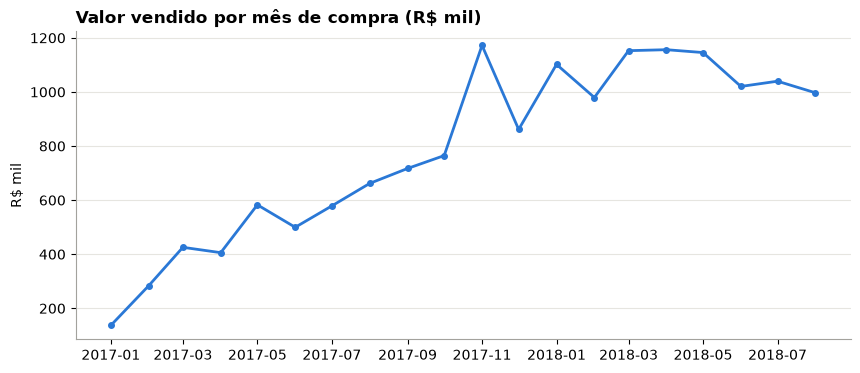

In [10]:
vendas['mes'] = vendas['order_purchase_timestamp'].dt.to_period('M')
por_mes = vendas.groupby('mes').agg(pedidos=('order_id', 'size'),
                                    valor_vendido=('valor', 'sum'),
                                    ticket_mediano=('valor', 'median'))
print(por_mes.round(1))

plt.figure()
plt.plot(por_mes.index.to_timestamp(), por_mes['valor_vendido'] / 1000, color=AZUL, linewidth=2, marker='o', markersize=4)
plt.title('Valor vendido por mês de compra (R$ mil)')
plt.ylabel('R$ mil')
plt.show()

- O valor vendido sai de **R\$ 137 mil** em jan/2017 e passa de **R\$ 1 milhão por mês** a partir de jan/2018.
- O pico é **nov/2017 (R\$ 1,17 milhão)**, o mesmo mês do pico de pedidos da Black Friday.
- Em 2018 o valor vendido fica estável entre R\$ 1,0 e 1,16 milhão por mês.

Comparo os mesmos meses dos dois anos (jan a ago), para não misturar o efeito de nov e dez.

In [11]:
ano_2017 = por_mes.loc['2017-01':'2017-08'].sum()
ano_2018 = por_mes.loc['2018-01':'2018-08'].sum()

print(f'Pedidos: {ano_2017["pedidos"]:,.0f} -> {ano_2018["pedidos"]:,.0f} ({(ano_2018["pedidos"] / ano_2017["pedidos"] - 1) * 100:.0f}%)')
print(f'Valor vendido: R$ {ano_2017["valor_vendido"]:,.0f} -> R$ {ano_2018["valor_vendido"]:,.0f} ({(ano_2018["valor_vendido"] / ano_2017["valor_vendido"] - 1) * 100:.0f}%)')

Pedidos: 22,562 -> 53,531 (137%)
Valor vendido: R$ 3,574,992 -> R$ 8,593,138 (140%)


De jan-ago/2017 para jan-ago/2018, os pedidos crescem **137%** e o valor vendido cresce **140%**. Os dois números quase coincidem.

**Hipótese:** o valor vendido cresce porque há **mais pedidos**, e não porque cada pedido ficou mais caro. Se for assim, o ticket mediano por mês fica estável.

## 2.7 Ticket mediano por mês

Uso a mediana do valor do pedido, pela decisão do item 2.5.

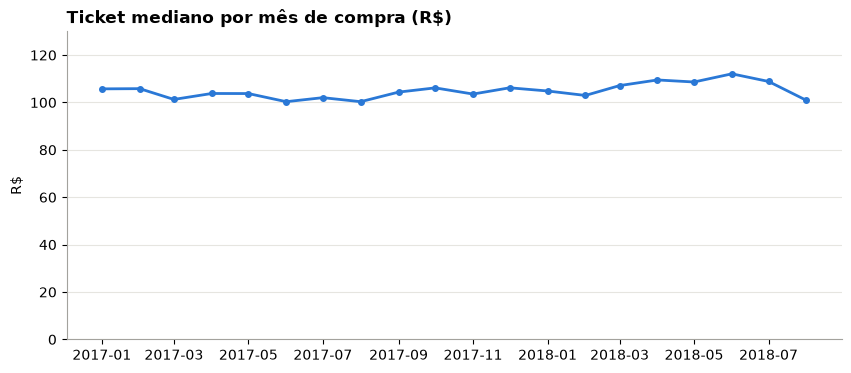

Ticket mediano no recorte: R$ 105.28 (média: R$ 160.19)


In [12]:
plt.figure()
plt.plot(por_mes.index.to_timestamp(), por_mes['ticket_mediano'], color=AZUL, linewidth=2, marker='o', markersize=4)
plt.ylim(0, 130)
plt.title('Ticket mediano por mês de compra (R$)')
plt.ylabel('R$')
plt.show()

print(f'Ticket mediano no recorte: R$ {vendas["valor"].median():.2f} (média: R$ {vendas["valor"].mean():.2f})')

- O ticket mediano fica entre **R\$ 100 e R\$ 112** em todos os 20 meses. O eixo começa no zero para não exagerar a variação.
- No recorte inteiro, o pedido típico custa **R\$ 105,28** (a média é R\$ 160,19, puxada pelos pedidos caros).

**Leitura:** a hipótese se sustenta. **A Olist cresce em valor vendido, e o crescimento vem do número de pedidos**: o valor de cada pedido praticamente não muda. Resta saber se esse valor é confiável, o que testo comparando com o que os clientes pagaram.

## 3.1 Leitura da tabela de pagamentos

In [13]:
payments = pd.read_csv('../data/raw/olist_order_payments_dataset.csv')
print(payments.shape)
payments.head()

(103886, 5)


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


**103.886 linhas**, de novo mais que os 99.441 pedidos. Cada linha tem um `payment_sequential` (1, 2...), o tipo, o número de parcelas e o valor.

**Hipótese:** um mesmo pedido pode ser pago de mais de uma forma, e cada forma vira uma linha.

## 3.2 Granularidade: quantos pagamentos tem cada pedido

Mesmo teste do item 2.2: conto as linhas por pedido. Depois, olho o tipo de pagamento só nos pedidos com mais de uma linha.

In [14]:
pagamentos_por_pedido = payments.groupby('order_id').size()
print(pagamentos_por_pedido.value_counts().sort_index().head())

com_varios = payments[payments['order_id'].isin(pagamentos_por_pedido[pagamentos_por_pedido > 1].index)]
print()
print(com_varios['payment_type'].value_counts())

1    96479
2     2382
3      301
4      108
5       52
Name: count, dtype: int64

payment_type
voucher        4581
credit_card    2823
debit_card        3
Name: count, dtype: int64


- **96.479 pedidos** (97%) têm um único pagamento.
- Nos pedidos com mais de um, predominam **voucher** (4.581 linhas) e **cartão de crédito** (2.823): o cliente usa um vale e completa com o cartão, ou usa vários vales.

A hipótese se confirma: a tabela está no nível de **pagamento**, e o valor pago por pedido é a soma das linhas.

## 3.3 Vazios, duplicatas e ligação com pedidos

In [15]:
print('Vazios:', payments.isnull().sum().sum())
print('Linhas idênticas:', payments.duplicated().sum())
print('Pagamentos sem pedido:', (~payments['order_id'].isin(orders['order_id'])).sum())
print('Pedidos sem pagamento:', (~orders['order_id'].isin(payments['order_id'])).sum())
print()
print('Pagamentos com valor zero:')
print(payments.loc[payments['payment_value'] == 0, 'payment_type'].value_counts())

Vazios: 0
Linhas idênticas: 0
Pagamentos sem pedido: 0
Pedidos sem pagamento: 1

Pagamentos com valor zero:
payment_type
voucher        6
not_defined    3
Name: count, dtype: int64


- Nenhum vazio, nenhuma duplicata, nenhum pagamento órfão.
- **1 pedido sem pagamento**, e **9 pagamentos de valor zero** (6 vouchers e 3 com tipo `not_defined`).

São casos isolados, sem peso no valor vendido. **Decisão:** ficam registrados como limitação; não removo nada.

## 3.4 O valor dos itens bate com o valor pago?

Este é o teste de confiança do valor vendido. Resumo os pagamentos por pedido e comparo, pedido a pedido, com o valor dos itens (preço + frete) calculado no item 2.6. Considero igual uma diferença de até 1 centavo.

In [16]:
pago = payments.groupby('order_id').agg(pago=('payment_value', 'sum'),
                                        parcelas=('payment_installments', 'max'))
conferencia = valor_pedido.join(pago, how='inner')
conferencia['diferenca'] = (conferencia['pago'] - conferencia['valor']).round(2)

igual = conferencia['diferenca'].abs() <= 0.01
pagou_mais = conferencia['diferenca'] > 0.01
pagou_menos = conferencia['diferenca'] < -0.01

print(f'Pedidos comparados: {len(conferencia):,}')
print(f'Valor igual: {igual.sum():,} ({igual.mean() * 100:.1f}%)')
print(f'Pagou mais: {pagou_mais.sum()}')
print(f'Pagou menos: {pagou_menos.sum()}')

Pedidos comparados: 98,665
Valor igual: 98,362 (99.7%)
Pagou mais: 264
Pagou menos: 39


**99,7%** dos pedidos têm valor pago igual ao valor dos itens, ao centavo. Sobram **264** que pagaram mais e **39** que pagaram menos.

**Hipótese para quem pagou mais:** juros de parcelamento. Se for isso, esses pedidos devem ser parcelados com muito mais frequência que os pedidos de valor igual. Comparo a proporção de parcelados (mais de 1 parcela) e a diferença típica em cada grupo.

In [17]:
for nome, grupo in [('Valor igual', igual), ('Pagou mais', pagou_mais), ('Pagou menos', pagou_menos)]:
    parte = conferencia[grupo]
    print(f'{nome}: {(parte["parcelas"] > 1).mean() * 100:.0f}% parcelados, diferença mediana R$ {parte["diferenca"].median():.2f}')

Valor igual: 51% parcelados, diferença mediana R$ 0.00
Pagou mais: 94% parcelados, diferença mediana R$ 6.48
Pagou menos: 51% parcelados, diferença mediana R$ -0.04


- Quem **pagou mais** é parcelado em **94%** dos casos, contra 51% de quem pagou o valor igual. A diferença mediana é de R\$ 6,48. **Compatível com juros de parcelamento.**
- Quem **pagou menos** tem diferença mediana de R\$ 0,04: arredondamento.

**Leitura:** o valor dos itens confere com o que os clientes pagaram. O valor vendido calculado no item 2.6 é confiável.

## 3.5 O risco de juntar itens e pagamentos direto

As duas tabelas têm mais de uma linha por pedido. Se eu juntar as duas sem resumir, um pedido com 2 itens e 2 pagamentos vira 4 linhas, e cada pagamento é contado duas vezes. Para medir o efeito, faço esse merge direto e comparo o total pago com o total correto.

In [18]:
juncao_direta = items.merge(payments, on='order_id')
print(f'Linhas: {len(items):,} itens x {len(payments):,} pagamentos -> {len(juncao_direta):,}')
print(f'Total pago correto:        R$ {payments["payment_value"].sum():,.2f}')
print(f'Total pago na junção direta: R$ {juncao_direta["payment_value"].sum():,.2f}')
print(f'Inflação: {(juncao_direta["payment_value"].sum() / payments["payment_value"].sum() - 1) * 100:.0f}%')

Linhas: 112,650 itens x 103,886 pagamentos -> 117,601
Total pago correto:        R$ 16,008,872.12
Total pago na junção direta: R$ 20,308,134.71
Inflação: 27%


A junção direta gera **117.601 linhas** e infla o total pago de **R\$ 16,0 milhões para R\$ 20,3 milhões (+27%)**. Um relatório que somasse esse campo mostraria ao investidor um valor vendido 27% maior que o real.

**Decisão:** toda tabela com mais de uma linha por pedido é **resumida por pedido antes de qualquer junção**. O valor vendido vem dos itens, que permitem abrir por produto e vendedor; os pagamentos servem para o meio de pagamento.

## 3.6 Como o cliente paga

Com `value_counts(normalize=True)` vejo a participação de cada tipo de pagamento, desenho em barras horizontais e, no cartão, calculo a mediana de parcelas. Os 3 pagamentos `not_defined` (todos de valor zero, item 3.3) ficam fora do gráfico.

payment_type
credit_card    73.9
boleto         19.0
voucher         5.6
debit_card      1.5
not_defined     0.0
Name: proportion, dtype: float64


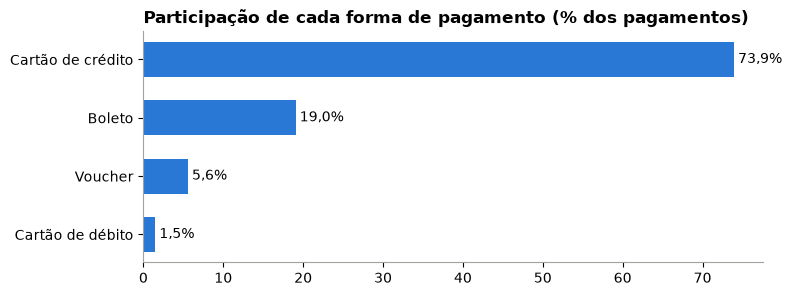

Parcelas no cartão (mediana): 3.0


In [19]:
participacao = payments['payment_type'].value_counts(normalize=True) * 100
print(participacao.round(1))

nomes = {'credit_card': 'Cartão de crédito', 'boleto': 'Boleto', 'voucher': 'Voucher', 'debit_card': 'Cartão de débito'}
grafico = participacao.drop('not_defined').rename(nomes).sort_values()

plt.figure(figsize=(8, 3))
barras = plt.barh(grafico.index, grafico.values, color=AZUL, height=0.6)
plt.bar_label(barras, labels=[f'{v:.1f}%'.replace('.', ',') for v in grafico.values], padding=3)
plt.grid(False)
plt.title('Participação de cada forma de pagamento (% dos pagamentos)')
plt.show()

cartao = payments[payments['payment_type'] == 'credit_card']
print('Parcelas no cartão (mediana):', cartao['payment_installments'].median())

- **Cartão de crédito: 73,9%** dos pagamentos. Boleto vem depois, com 19,0%. Voucher (5,6%) e débito (1,5%) são pequenos.
- No cartão, a mediana é de **3 parcelas** para um pedido típico de cerca de R\$ 105: o cliente parcela mesmo compras baratas.

## Resumo de itens e pagamentos

| # | Verificação | O que os dados mostraram | Decisão |
|---|---|---|---|
| 2.2 | Granularidade dos itens | uma linha por item; quantidade vira linhas repetidas | valor do pedido = soma das linhas |
| 2.3 | Vazios e duplicatas | nenhum | chave: `order_id` + `order_item_id` |
| 2.4 | Ligação com pedidos | nenhum item órfão; 775 pedidos sem item, quase todos cancelados ou indisponíveis | sem impacto no valor vendido |
| 2.5 | Preço | média 60% acima da mediana; 7,5% dos itens acima do limite do boxplot; frete sobe com o preço (correlação 0,41) | manter; pedido típico pela mediana |
| 2.6 | Valor vendido | R\$ 15,68 mi no recorte (14% de frete); pico em nov/2017 | valor vendido = preço + frete, sem cancelados e indisponíveis; receita e lucro da Olist não estão na base |
| 2.7 | Ticket | mediana estável entre R\$ 100 e R\$ 112 | crescimento explicado pelo volume |
| 3.2 | Granularidade dos pagamentos | uma linha por forma de pagamento; vários pagamentos = voucher + cartão | valor pago = soma das linhas |
| 3.3 | Qualidade | 1 pedido sem pagamento, 9 pagamentos zerados | limitação registrada |
| 3.4 | Itens x pagamentos | 99,7% iguais ao centavo; diferenças explicadas por juros e arredondamento | valor vendido dos itens é confiável |
| 3.5 | Junção direta | +27% no total pago | resumir por pedido antes de juntar |

**Resposta à pergunta:** sim. De jan-ago/2017 para jan-ago/2018, o valor vendido cresce 140%, acompanhando o número de pedidos, com ticket estável. O valor vendido confere com o valor pago em 99,7% dos pedidos.